# Random Forest Model for UFC Winner Prediction

This notebook builds a Random Forest classifier using the processed fight datasets. Random Forests are an ensemble of decision trees that average predictions to reduce overfitting and provide built-in feature importance rankings.

## Imports: Libraries Used in This Notebook

This code block imports all required packages for:
1. Data loading and manipulation (`pandas`, `numpy`).
2. Plotting (`matplotlib`, `seaborn`).
3. Model building (`RandomForestClassifier`).
4. Hyperparameter tuning (`RandomizedSearchCV`).
5. Model evaluation (`accuracy`, `precision`, `recall`, `F1`, `ROC-AUC`, confusion matrix, classification report).
6. Saving trained models (`joblib`).

In [1]:
from pathlib import Path

import numpy as np
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import randint

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

## Paths and Data Loading

This code block defines project/data/model paths, reads the train/validation/test processed CSV files, and prints their shapes so you can verify the splits loaded correctly.

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# train_df = pd.read_csv(DATA_DIR / "fights_training.csv")
# val_df   = pd.read_csv(DATA_DIR / "fights_validation.csv")
# test_df  = pd.read_csv(DATA_DIR / "fights_testing.csv")

# train_df = pd.read_csv(DATA_DIR / "fights_training_exp1.csv")
# val_df   = pd.read_csv(DATA_DIR / "fights_validation_exp1.csv")
# test_df  = pd.read_csv(DATA_DIR / "fights_testing_exp1.csv")

train_df = pd.read_csv(DATA_DIR / "fights_training_exp2.csv")
val_df   = pd.read_csv(DATA_DIR / "fights_validation_exp2.csv")
test_df  = pd.read_csv(DATA_DIR / "fights_testing_exp2.csv")

print(f"Train:      {train_df.shape}")
print(f"Validation: {val_df.shape}")
print(f"Test:       {test_df.shape}")

Train:      (5212, 66)
Validation: (744, 66)
Test:       (1492, 66)


## Define Target, Features, and Split X / y

Random Forests do not require feature scaling, so no StandardScaler is used.

In [3]:
TARGET = "winner"
COLUMNS_TO_DROP = {"is_mirror", "is_mirrored", "fight_id", "fight_index", "index"}

columns_to_exclude = {
    col
    for col in train_df.columns
    if col in COLUMNS_TO_DROP or "fight_index" in col.lower()
}

features = [col for col in train_df.columns if col != TARGET and col not in columns_to_exclude]

X_train = train_df[features]
y_train = train_df[TARGET]

X_val = val_df[features]
y_val = val_df[TARGET]

X_test = test_df[features]
y_test = test_df[TARGET]

print(f"Dropped columns: {sorted(columns_to_exclude)}")
print(f"Features: {len(features)}")
print(features)

Dropped columns: ['fight_id', 'is_mirror']
Features: 63
['f1_age_during', 'f2_age_during', 'mens_class_encoded', 'womens_class_encoded', 'f1_orthodox', 'f1_southpaw', 'f1_switch', 'f2_orthodox', 'f2_southpaw', 'f2_switch', 'diff_fighter_dob', 'diff_height_cm', 'diff_knockdowns', 'diff_sig_strike_atts', 'diff_sig_strikes', 'diff_tot_strike_atts', 'diff_tot_strikes', 'diff_takedown_atts', 'diff_takedowns', 'diff_submissions', 'diff_reversals', 'diff_ctrl_time', 'diff_head_strike_atts', 'diff_head_strikes', 'diff_body_strike_atts', 'diff_body_strikes', 'diff_leg_strike_atts', 'diff_leg_strikes', 'diff_dist_strike_atts', 'diff_dist_strikes', 'diff_clinch_atts', 'diff_clinchs', 'diff_ground_atts', 'diff_grounds', 'diff_total_fight_time', 'diff_experience', 'diff_wins', 'diff_losses', 'diff_fighter_weight_lbs', 'diff_fighter_reach_cm', 'diff_knockdowns_last4', 'diff_sig_strike_atts_last4', 'diff_sig_strikes_last4', 'diff_tot_strike_atts_last4', 'diff_tot_strikes_last4', 'diff_takedown_atts_l

## Baseline Random Forest

Train a default Random Forest on the training set and evaluate on the validation set to establish a pre-tuning benchmark.

In [4]:
baseline_rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
baseline_rf.fit(X_train, y_train)

baseline_val_pred = baseline_rf.predict(X_val)
baseline_val_acc  = accuracy_score(y_val, baseline_val_pred)
print(f"Baseline validation accuracy: {baseline_val_acc:.4f}")

Baseline validation accuracy: 0.6425


## Hyperparameter Tuning with RandomizedSearchCV

A randomized search samples `n_iter` combinations from the parameter distributions and uses 5-fold cross-validation on the training set to identify the best settings. This is more efficient than an exhaustive grid search.

In [5]:
param_distributions = {
    "n_estimators":      randint(100, 601),
    "max_depth":         [None, 5, 10, 15, 20, 25],
    "min_samples_split": randint(2, 21),
    "min_samples_leaf":  randint(1, 11),
    "max_features":      ["sqrt", "log2", 0.5],
    "class_weight":      [None, "balanced"],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=60,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

rf_search.fit(X_train, y_train)

print("\nBest parameters:")
print(rf_search.best_params_)
print(f"Best CV accuracy: {rf_search.best_score_:.4f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits


/opt/homebrew/Caskroom/miniconda/base/envs/UFC/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/UFC/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/UFC/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/


Best parameters:
{'class_weight': 'balanced', 'max_depth': 15, 'max_features': 'log2', 'min_samples_leaf': 10, 'min_samples_split': 8, 'n_estimators': 289}
Best CV accuracy: 0.5948


## Evaluate the Tuned Model on Validation and Test Sets

In [6]:
best_rf = rf_search.best_estimator_

train_pred = best_rf.predict(X_train)
train_prob = best_rf.predict_proba(X_train)[:, 1]

val_pred  = best_rf.predict(X_val)
val_prob  = best_rf.predict_proba(X_val)[:, 1]

test_pred = best_rf.predict(X_test)
test_prob = best_rf.predict_proba(X_test)[:, 1]

train_metrics = {
    "accuracy":  accuracy_score(y_train, train_pred),
    "precision": precision_score(y_train, train_pred, zero_division=0),
    "recall":    recall_score(y_train, train_pred, zero_division=0),
    "f1":        f1_score(y_train, train_pred, zero_division=0),
    "log_loss":  log_loss(y_train, train_prob),
    "roc_auc":   roc_auc_score(y_train, train_prob),
}

val_metrics = {
    "accuracy":  accuracy_score(y_val, val_pred),
    "precision": precision_score(y_val, val_pred, zero_division=0),
    "recall":    recall_score(y_val, val_pred, zero_division=0),
    "f1":        f1_score(y_val, val_pred, zero_division=0),
    "log_loss":  log_loss(y_val, val_prob),
    "roc_auc":   roc_auc_score(y_val, val_prob),
}

test_metrics = {
    "accuracy":  accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall":    recall_score(y_test, test_pred, zero_division=0),
    "f1":        f1_score(y_test, test_pred, zero_division=0),
    "log_loss":  log_loss(y_test, test_prob),
    "roc_auc":   roc_auc_score(y_test, test_prob),
}

metrics_df = pd.DataFrame(
    [train_metrics, val_metrics, test_metrics],
    index=["train", "validation", "test"],
)
display(metrics_df)

print("\nValidation classification report:")
print(classification_report(y_val, val_pred, digits=4))

print("\nTest classification report:")
print(classification_report(y_test, test_pred, digits=4))

,accuracy,precision,recall,f1,log_loss,roc_auc
train,0.899463,0.900077,0.898695,0.899386,0.479360,0.969267
validation,0.659946,0.659517,0.661290,0.660403,0.636896,0.700789
test,0.615282,0.614058,0.620643,0.617333,0.644918,0.676671



Validation classification report:
              precision    recall  f1-score   support

           0     0.6604    0.6586    0.6595       372
           1     0.6595    0.6613    0.6604       372

    accuracy                         0.6599       744
   macro avg     0.6599    0.6599    0.6599       744
weighted avg     0.6599    0.6599    0.6599       744


Test classification report:
              precision    recall  f1-score   support

           0     0.6165    0.6099    0.6132       746
           1     0.6141    0.6206    0.6173       746

    accuracy                         0.6153      1492
   macro avg     0.6153    0.6153    0.6153      1492
weighted avg     0.6153    0.6153    0.6153      1492



## Save Validation Predictions to CSV

In [7]:
validation_output_path = DATA_DIR / "random_forest_validation_predictions.csv"

validation_results = X_val.reset_index(drop=True).copy()
validation_results["actual_label"]     = y_val.reset_index(drop=True)
validation_results["predicted_label"]  = val_pred
validation_results["prob_fighter_a_win"] = val_prob
validation_results["prob_fighter_b_win"] = 1 - val_prob
validation_results["correct"] = (validation_results["actual_label"] == validation_results["predicted_label"]).astype(int)

validation_results.to_csv(validation_output_path, index=False)
print(f"Saved validation predictions to: {validation_output_path}")

Saved validation predictions to: /Users/connormcilhinney/Desktop/GithubRepos/Machine-Learning-Project/data/processed/random_forest_validation_predictions.csv


## ROC Curve

Plots the ROC curve for both the validation and test splits. Curves closer to the top-left corner indicate stronger class separation.

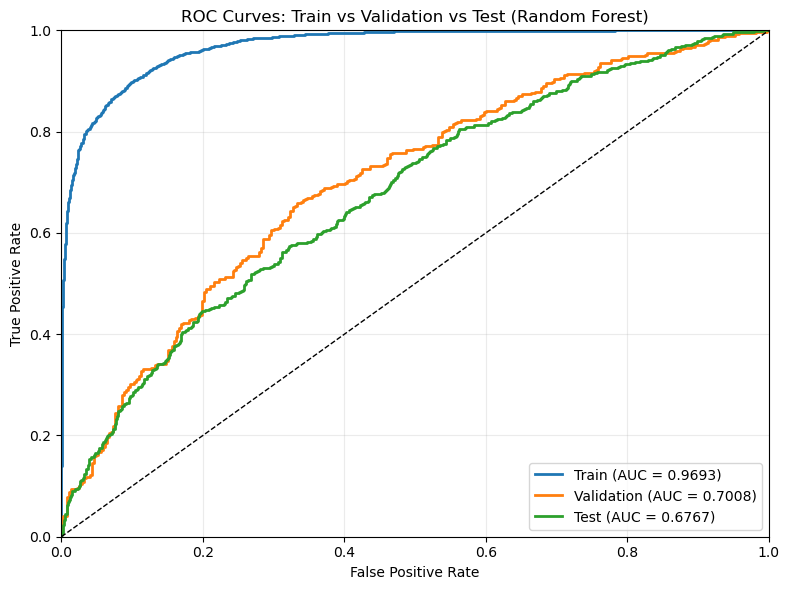

In [8]:
train_auc = roc_auc_score(y_train, train_prob)
val_auc   = roc_auc_score(y_val, val_prob)
test_auc  = roc_auc_score(y_test, test_prob)

train_fpr, train_tpr, _ = roc_curve(y_train, train_prob)
val_fpr,   val_tpr,   _ = roc_curve(y_val, val_prob)
test_fpr,  test_tpr,  _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(8, 6))
plt.plot(train_fpr, train_tpr, linewidth=2, label=f"Train (AUC = {train_auc:.4f})")
plt.plot(val_fpr, val_tpr, linewidth=2, label=f"Validation (AUC = {val_auc:.4f})")
plt.plot(test_fpr, test_tpr, linewidth=2, label=f"Test (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Train vs Validation vs Test (Random Forest)")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Confusion Matrix

Shows true vs predicted labels on the test set. Rows are actual labels; columns are predicted labels.

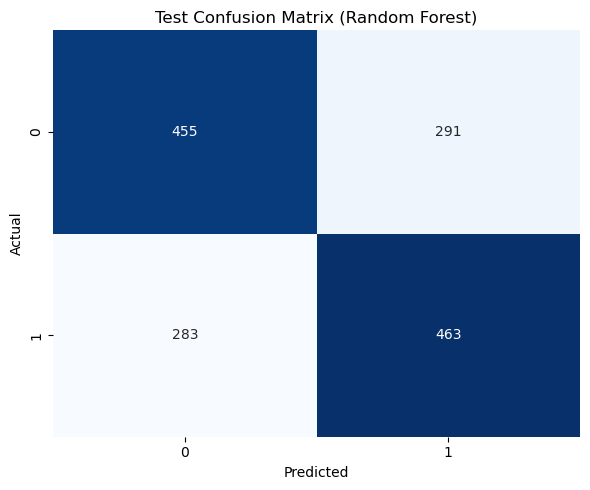

In [9]:
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Test Confusion Matrix (Random Forest)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## Feature Importance

Random Forests compute mean decrease in impurity (Gini importance) across all trees for each feature. Higher values mean the feature was used more often and produced larger splits.

/var/folders/g3/zmhjghbx599gjzn3783w82mc0000gn/T/ipykernel_99544/1709720460.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_feats, x="importance", y="feature", palette="Blues_r")


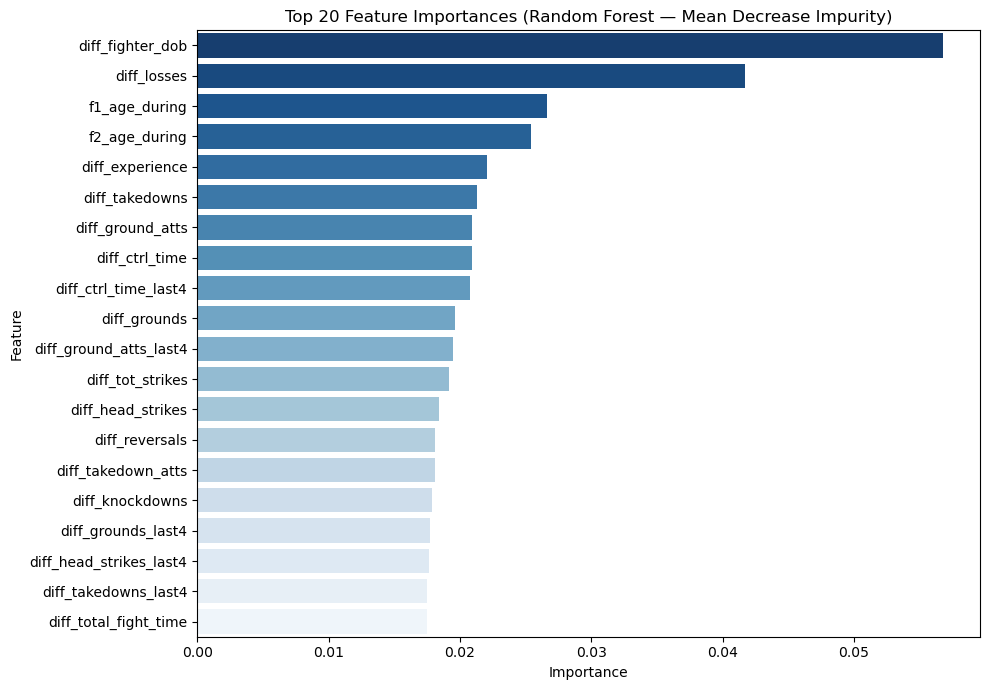


Top 20 features:


,feature,importance
0,diff_fighter_dob,0.056758
1,diff_losses,0.041737
2,f1_age_during,0.026591
3,f2_age_during,0.025416
4,diff_experience,0.022037
5,diff_takedowns,0.021267
6,diff_ground_atts,0.020944
7,diff_ctrl_time,0.020915
8,diff_ctrl_time_last4,0.020784
9,diff_grounds,0.019586


In [10]:
importances = best_rf.feature_importances_
feat_imp_df = (
    pd.DataFrame({"feature": features, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

top_n = 20
top_feats = feat_imp_df.head(top_n)

plt.figure(figsize=(10, 7))
sns.barplot(data=top_feats, x="importance", y="feature", palette="Blues_r")
plt.title(f"Top {top_n} Feature Importances (Random Forest — Mean Decrease Impurity)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(f"\nTop {top_n} features:")
display(top_feats)

## Feature-Focused Accuracy Plots

Bins the top features by value range and plots per-bin accuracy on the test set to reveal where the model performs best and worst.

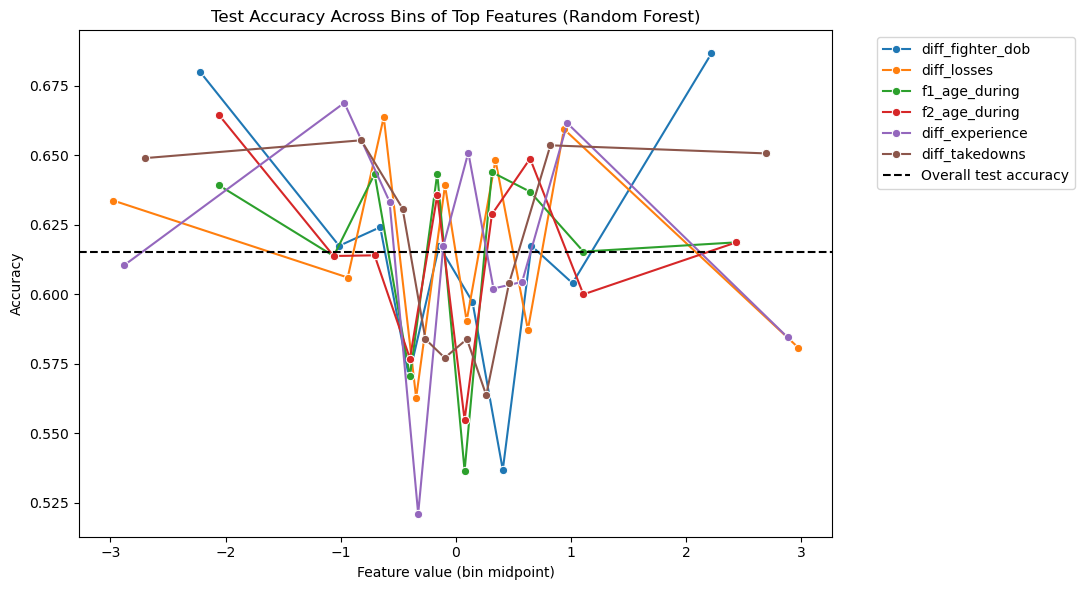

In [11]:
top_plot_n = 6
top_plot_features = top_feats.head(top_plot_n)["feature"].tolist()

plot_df = X_test[top_plot_features].copy()
plot_df["correct"] = (test_pred == y_test.to_numpy()).astype(int)

binned_rows = []
for feature in top_plot_features:
    try:
        bins = pd.qcut(plot_df[feature], q=10, duplicates="drop")
    except ValueError:
        continue

    feature_bins = pd.DataFrame({"bin": bins, "correct": plot_df["correct"]})
    summary = feature_bins.groupby("bin", observed=False)["correct"].mean().reset_index(name="accuracy")
    summary["feature"]  = feature
    summary["bin_mid"]  = summary["bin"].apply(lambda interval: interval.mid)
    binned_rows.append(summary)

if binned_rows:
    binned_accuracy = pd.concat(binned_rows, ignore_index=True)

    plt.figure(figsize=(11, 6))
    sns.lineplot(data=binned_accuracy, x="bin_mid", y="accuracy", hue="feature", marker="o")
    plt.axhline(accuracy_score(y_test, test_pred), color="black", linestyle="--", label="Overall test accuracy")
    plt.title("Test Accuracy Across Bins of Top Features (Random Forest)")
    plt.xlabel("Feature value (bin midpoint)")
    plt.ylabel("Accuracy")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("Could not build binned feature plot (insufficient unique values).")

## Save the Trained Model

Saves the best Random Forest pipeline as a `.joblib` artifact for reuse in later notebooks or scripts.

In [12]:
model_path = MODEL_DIR / "random_forest.joblib"
joblib.dump(best_rf, model_path)
print(f"Saved model to: {model_path}")

Saved model to: /Users/connormcilhinney/Desktop/GithubRepos/Machine-Learning-Project/models/random_forest.joblib
